# Exploring NASA MODIS climate data via GIBS

**Phase 1: setup.** This section builds the helpers used in the rest of the notebook:

1. **Catalog**: list every MODIS layer GIBS serves, with its available dates and color map.
2. **Fetch**: download a layer for one date and bounding box as a PNG (cached on disk).
3. **Decode**: convert pixel colors back to physical values using the layer's published color map.
4. **Check**: confirm the decoded values are physically sensible.

**Why decoding is needed.** GIBS serves *rendered images*, not raw science data. Each layer has a color map XML
that lists which RGB color stands for which value range. Every visible pixel matches a color map entry exactly,
so the reverse lookup is lossless, except that values come back binned (about 100–250 bins per layer).
Each bin is represented by its midpoint. The first and last bins are open-ended catch-alls (e.g. LST `[350 K, 652 K)`),
so they are represented by their inner edge, which clips extreme values.

In [1]:
import io
import re
import time
import hashlib
import xml.etree.ElementTree as ET
from dataclasses import dataclass, field
from datetime import date
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from PIL import Image

GIBS = "https://gibs.earthdata.nasa.gov"
WMS_URL = f"{GIBS}/wms/epsg4326/best/wms.cgi"
WMTS_CAPS_URL = f"{GIBS}/wmts/epsg4326/best/1.0.0/WMTSCapabilities.xml"

CACHE = Path("data/cache")
CACHE.mkdir(parents=True, exist_ok=True)

session = requests.Session()
session.headers["User-Agent"] = "dsc106-climate-exploration/0.1"

pd.set_option("display.max_colwidth", 80)

## 1. Layer catalog

The WMTS capabilities document (~5 MB) lists every GIBS layer with its date ranges and color map link.
It's cached locally. Pass `refresh=True` to download it again (GIBS adds new dates daily).

In [3]:
NS = {
    "w": "http://www.opengis.net/wmts/1.0",
    "ows": "http://www.opengis.net/ows/1.1",
    "xlink": "http://www.w3.org/1999/xlink",
}
HREF = f"{{{NS['xlink']}}}href"


def cached_get(url, path, refresh=False, **params):
    """GET `url` once and keep the bytes at `path`."""
    path = Path(path)
    if path.exists() and not refresh:
        return path.read_bytes()
    r = session.get(url, params=params or None, timeout=120)
    r.raise_for_status()
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_bytes(r.content)
    return r.content


def load_catalog(refresh=False):
    xml = cached_get(WMTS_CAPS_URL, CACHE / "WMTSCapabilities.xml", refresh=refresh)
    root = ET.fromstring(xml)
    rows = []
    for layer in root.iter(f"{{{NS['w']}}}Layer"):
        hrefs = [m.get(HREF) or "" for m in layer.findall("ows:Metadata", NS)]
        rows.append({
            "layer": layer.find("ows:Identifier", NS).text,
            "title": layer.find("ows:Title", NS).text,
            "format": layer.find("w:Format", NS).text,
            "resolution": layer.find("w:TileMatrixSetLink/w:TileMatrixSet", NS).text,
            "time_ranges": [v.text for v in layer.findall("w:Dimension/w:Value", NS)],
            "colormap_url": next((h for h in hrefs if "/colormaps/v1.3/" in h), None),
            "legend_url": next((lg.get(HREF) for lg in layer.iter(f"{{{NS['w']}}}LegendURL")
                                if lg.get(HREF, "").endswith("_H.svg")), None),
        })
    return pd.DataFrame(rows).set_index("layer")


catalog = load_catalog()
modis = catalog[catalog.index.str.startswith("MODIS_")].copy()
print(f"{len(catalog)} GIBS layers, {len(modis)} MODIS layers")

1332 GIBS layers, 250 MODIS layers


Date ranges are written as `start/end/period`, e.g. `2000-03-01/2026-10-01/P1M`. A layer can list several ranges,
and the spaces between them are **gaps with no data**. `layer_dates()` expands them into individual dates.

In [4]:
PERIOD_RE = re.compile(r"^P(\d+)([DMY])$")


def expand_range(spec):
    """'2000-03-01/2000-06-01/P1M' -> DatetimeIndex of every date in the range."""
    parts = spec.split("/")
    if len(parts) == 1:
        return pd.DatetimeIndex([parts[0][:10]])
    start, end, period = parts
    m = PERIOD_RE.match(period)
    if m is None:                       # sub-daily periods (PT10M etc.): just keep the endpoints
        return pd.DatetimeIndex([start[:10], end[:10]])
    n, unit = int(m.group(1)), m.group(2)
    freq = {"D": f"{n}D", "M": f"{n}MS", "Y": f"{n}YS"}[unit]
    return pd.date_range(start[:10], end[:10], freq=freq)


def layer_dates(layer):
    ranges = catalog.loc[layer, "time_ranges"]
    return pd.DatetimeIndex(sorted(set().union(*[expand_range(r) for r in ranges])))


def summarize(layer):
    d = layer_dates(layer)
    period = catalog.loc[layer, "time_ranges"][0].split("/")[-1]
    out = {"first": d.min().date(), "last": d.max().date(), "n_dates": len(d), "period": period}
    if period == "P1M":                 # count missing months inside the span
        full = pd.date_range(d.min(), d.max(), freq="MS")
        missing = full.difference(d)
        out["n_missing"] = len(missing)
        out["missing_example"] = ", ".join(m.strftime("%Y-%m") for m in missing[:4]) + (" …" if len(missing) > 4 else "")
    return out

### Monthly MODIS layers

Monthly composites are the most useful starting point for a story over time: there are 25+ years of them and fewer cloud gaps than daily data.
`n_missing` counts months with no data between the first and last date.

In [5]:
monthly = [l for l in modis.index if any(r.endswith("/P1M") for r in modis.loc[l, "time_ranges"])]
monthly_summary = pd.DataFrame({l: summarize(l) for l in monthly}).T
monthly_summary["title"] = modis.loc[monthly, "title"]
monthly_summary["has_colormap"] = modis.loc[monthly, "colormap_url"].notna()
monthly_summary.sort_values("n_dates", ascending=False)

,first,last,n_dates,period,n_missing,missing_example,title,has_colormap
MODIS_Terra_L3_Land_Surface_Temp_Monthly_CMG_Day_TES,2000-02-01,2026-10-01,321,P1M,0,,"Land Surface Temperature (ASTER TES L3, Monthly, Day, MODIS, Terra)",True
MODIS_Terra_L3_Land_Surface_Temp_Monthly_CMG_Night_TES,2000-02-01,2026-10-01,321,P1M,0,,"Land Surface Temperature (ASTER TES L3, Monthly, Night, MODIS, Terra)",True
MODIS_Terra_L3_Land_Surface_Temp_Monthly_Day,2000-03-01,2026-10-01,320,P1M,0,,"Land Surface Temperature (L3, Monthly, Day, MODIS, Terra)",True
MODIS_Terra_L3_Land_Surface_Temp_Monthly_Night,2000-03-01,2026-10-01,320,P1M,0,,"Land Surface Temperature (L3, Monthly, Night, MODIS, Terra)",True
MODIS_Terra_L3_EVI_Monthly,2000-03-01,2026-10-01,319,P1M,1,2025-04,"Enhanced Vegetation Index (L3, Monthly, MODIS, Terra)",True
MODIS_Terra_L3_NDVI_Monthly,2000-03-01,2026-10-01,319,P1M,1,2025-04,"Vegetation Index (L3, Monthly, MODIS, Terra)",True
MODIS_Terra_L3_Snow_Cover_Monthly_Average_Pct,2000-03-01,2026-10-01,314,P1M,6,"2000-08, 2001-06, 2002-03, 2003-12 …","Snow Cover (L3, Monthly Average Percent, MODIS, Terra)",True
MODIS_Terra_L3_SST_Thermal_4km_Night_Monthly,2000-08-01,2026-04-01,304,P1M,5,"2022-10, 2022-12, 2023-01, 2024-01 …","Sea Surface Temperature (L3, Night, Monthly, Thermal, 4 km, MODIS, Terra)",True
MODIS_Terra_L3_SST_MidIR_4km_Night_Monthly,2000-08-01,2026-04-01,303,P1M,6,"2022-10, 2022-12, 2023-01, 2023-06 …","Sea Surface Temperature (L3, Night, Monthly, Mid Infrared, 4 km, MODIS, Terra)",True
MODIS_Terra_L3_SST_Thermal_9km_Night_Monthly,2000-08-01,2026-04-01,303,P1M,6,"2022-10, 2022-12, 2023-01, 2023-06 …","Sea Surface Temperature (L3, Night, Monthly, Thermal, 9 km, MODIS, Terra)",True


Search the full MODIS catalog by keyword:

In [6]:
def find_layers(pattern):
    hits = modis[modis.index.str.contains(pattern, case=False) | modis["title"].str.contains(pattern, case=False)]
    return hits[["title", "format", "resolution"]].assign(
        first=[layer_dates(l).min().date() for l in hits.index],
        last=[layer_dates(l).max().date() for l in hits.index],
    )

find_layers("snow")

,title,format,resolution,first,last
layer,,,,,
MODIS_Aqua_L3_Snow_Cover_Monthly_Average_Pct,"Snow Cover (L3, Monthly Average Percent, MODIS, Aqua)",image/png,2km,2002-07-04,2026-10-01
MODIS_Terra_L3_Snow_Cover_Monthly_Average_Pct,"Snow Cover (L3, Monthly Average Percent, MODIS, Terra)",image/png,2km,2000-03-01,2026-10-01
MODIS_Aqua_L3_NDSI_Snow_Cover_Daily,"Snow Cover (Normalized Difference Snow Index, L3, Daily, MODIS, Aqua)",image/png,500m,2002-07-04,2026-11-02
MODIS_Terra_L3_NDSI_Snow_Cover_Daily,"Snow Cover (Normalized Difference Snow Index, L3, Daily, MODIS, Terra)",image/png,500m,2000-02-24,2026-11-02
MODIS_Aqua_NDSI_Snow_Cover,"Snow Cover (Normalized Difference Snow Index, MODIS, Aqua)",image/png,500m,2002-07-03,2026-11-04
MODIS_Terra_NDSI_Snow_Cover,"Snow Cover (Normalized Difference Snow Index, MODIS, Terra)",image/png,500m,2000-02-24,2026-11-05
MODIS_Aqua_L3_Snow_Extent_8Day,"Snow Extent (L3, 8-Day, MODIS, Aqua)",image/png,500m,2002-07-04,2026-10-24
MODIS_Terra_L3_Snow_Extent_8Day,"Snow Extent (L3, 8-Day, MODIS, Terra)",image/png,500m,2000-02-26,2026-10-24


## 2. Color maps

Each color map XML has one or more `<ColorMap>` blocks. Entries take several forms:

| Form | Example | Decoded as |
|---|---|---|
| range | `[0.02,200.00)` | midpoint (inner edge for the first and last bins) |
| single value | `[42]` or `42` | that value |
| open-ended | `[-INF,0.00)` / `[32.00,+INF)` | the finite edge |
| `nodata="true"` | | NaN |
| no `value` (classification) | e.g. "Cloud", "Ocean" in the snow layer | NaN, with its label kept in `.classes` |

**Caveat:** `transparent="true"` entries come back as fully transparent pixels, which look the same as "no data".
For example, NDVI below −0.1 (water) and **0% snow cover** are both transparent, so they decode to NaN.
Keep this in mind before averaging snow cover.

In [7]:
NUM = r"([+-]?(?:INF|\d*\.?\d+(?:[eE][+-]?\d+)?))"
RANGE_RE = re.compile(rf"^\s*[\[(]{NUM}\s*,\s*{NUM}\s*[\])]\s*$")
SINGLE_RE = re.compile(rf"^\s*\[?{NUM}\]?\s*$")


def _num(s):
    s = s.upper()
    return float("inf") if s in ("INF", "+INF") else float("-inf") if s == "-INF" else float(s)


def rgb_key(r, g, b):
    return (np.asarray(r, np.int64) << 16) | (np.asarray(g, np.int64) << 8) | np.asarray(b, np.int64)


@dataclass
class Colormap:
    title: str
    units: str | None
    keys: np.ndarray          # packed RGB, sorted
    values: np.ndarray        # decoded value per key (NaN = nodata / class)
    classes: dict = field(default_factory=dict)   # packed RGB -> label for classification colors
    n_numeric: int = 0

    def __repr__(self):
        lo, hi = np.nanmin(self.values), np.nanmax(self.values)
        return (f"Colormap({self.title!r}, units={self.units!r}, {self.n_numeric} numeric bins "
                f"[{lo:g} … {hi:g}], {len(self.classes)} classes)")


def parse_colormap(xml_bytes):
    root = ET.fromstring(xml_bytes)
    keys, values, classes = [], [], {}
    title = units = None
    numeric = []                                   # (index, lo, hi) to fix up edge bins afterwards
    for cm in root.iter("ColorMap"):
        tooltips = {le.get("id"): le.get("tooltip") for le in cm.iter("LegendEntry")}
        for e in cm.iter("ColorMapEntry"):
            key = int(rgb_key(*map(int, e.get("rgb").split(","))))
            v = e.get("value")
            if e.get("nodata") == "true" or v is None:
                keys.append(key); values.append(np.nan)
                classes[key] = e.get("label") or tooltips.get(e.get("ref")) or ("No Data" if e.get("nodata") == "true" else "class")
                continue
            if title is None:
                title, units = cm.get("title"), cm.get("units")
            if (m := RANGE_RE.match(v)):
                lo, hi = _num(m.group(1)), _num(m.group(2))
                numeric.append((len(values), lo, hi))
                val = lo if np.isinf(hi) else hi if np.isinf(lo) else (lo + hi) / 2
            elif (m := SINGLE_RE.match(v)):
                val = _num(m.group(1))
            else:
                raise ValueError(f"unrecognized colormap value {v!r}")
            keys.append(key); values.append(val)
    # first/last numeric range bins are catch-alls: use their inner edge
    if len(numeric) >= 2:
        numeric.sort(key=lambda t: t[1])
        (i0, _, hi0), (i1, lo1, _) = numeric[0], numeric[-1]
        values[i0], values[i1] = (hi0 if np.isfinite(hi0) else values[i0]), (lo1 if np.isfinite(lo1) else values[i1])
    keys, values = np.array(keys, np.int64), np.array(values, float)
    order = np.argsort(keys, kind="stable")
    keys, idx = np.unique(keys[order], return_index=True)   # keep first entry if a color repeats
    values = values[order][idx]
    return Colormap(title, units, keys, values, classes, int(np.isfinite(values).sum()))


def load_colormap(layer):
    url = catalog.loc[layer, "colormap_url"]
    if url is None:
        raise ValueError(f"{layer} has no color map (it may be imagery or vector data)")
    return parse_colormap(cached_get(url, CACHE / "colormaps" / Path(url).name))


load_colormap("MODIS_Terra_L3_Land_Surface_Temp_Monthly_Day")

Colormap('Land Surface Temperature', units='K', 252 numeric bins [200 … 350.02], 1 classes)

## 3. Fetching and decoding grids

`get_grid()` requests the layer from the GIBS **WMS** endpoint for any bounding box and pixel size, then decodes it.

- The default is a global 720×360 image, i.e. **0.5° per pixel**. That's a good resolution for exploring.
  For a region, pass a smaller `bbox` and a larger `width` to zoom in.
- `bbox` is `(west, south, east, north)` in degrees. Note that WMS 1.3.0 with EPSG:4326 expects *lat, lon* order;
  the function handles the conversion.
- PNGs are cached under `data/cache/wms/<layer>/`, so re-running the notebook makes no network requests.

The result is a small `Grid` object with `.values`, `.lats`, `.lons`, `.sel()` for cropping,
an area-weighted `.mean()`, and `.plot()`.

In [8]:
GLOBAL = (-180, -90, 180, 90)


def fetch_png(layer, when, bbox=GLOBAL, width=720, height=None, refresh=False):
    """Return the WMS image as an (H, W, 4) uint8 RGBA array."""
    west, south, east, north = bbox
    if height is None:                               # keep pixels square in degrees
        height = max(1, round(width * (north - south) / (east - west)))
    when = pd.Timestamp(when).strftime("%Y-%m-%d")
    tag = hashlib.md5(f"{bbox}".encode()).hexdigest()[:8]
    path = CACHE / "wms" / layer / f"{when}_{tag}_{width}x{height}.png"
    if not path.exists() or refresh:
        params = dict(SERVICE="WMS", REQUEST="GetMap", VERSION="1.3.0", LAYERS=layer,
                      CRS="EPSG:4326", BBOX=f"{south},{west},{north},{east}",
                      WIDTH=width, HEIGHT=height, FORMAT="image/png", TIME=when)
        for attempt in range(3):
            r = session.get(WMS_URL, params=params, timeout=120)
            if r.ok and r.headers.get("content-type", "").startswith("image/"):
                break
            time.sleep(2 ** attempt)
        else:
            raise RuntimeError(f"GIBS error for {layer} @ {when}: {r.status_code} {r.text[:300]}")
        path.parent.mkdir(parents=True, exist_ok=True)
        path.write_bytes(r.content)
    return np.array(Image.open(path).convert("RGBA"))


def decode(rgba, cmap):
    """Map RGBA pixels to values. Transparent / nodata / unmatched -> NaN."""
    key = rgb_key(rgba[..., 0], rgba[..., 1], rgba[..., 2])
    pos = np.clip(np.searchsorted(cmap.keys, key), 0, len(cmap.keys) - 1)
    matched = cmap.keys[pos] == key
    opaque = rgba[..., 3] > 0
    values = np.where(matched & opaque, cmap.values[pos], np.nan)
    unmatched = (opaque & ~matched).sum()
    return values, unmatched


@dataclass
class Grid:
    layer: str
    date: pd.Timestamp
    values: np.ndarray
    lats: np.ndarray       # pixel-center latitudes, north -> south
    lons: np.ndarray       # pixel-center longitudes, west -> east
    units: str | None = None
    title: str | None = None

    @property
    def extent(self):
        dlat, dlon = abs(self.lats[1] - self.lats[0]), abs(self.lons[1] - self.lons[0])
        return (self.lons[0] - dlon / 2, self.lons[-1] + dlon / 2, self.lats[-1] - dlat / 2, self.lats[0] + dlat / 2)

    def sel(self, lat=None, lon=None):
        """Crop to lat=(south, north), lon=(west, east)."""
        r = np.ones(len(self.lats), bool) if lat is None else (self.lats >= lat[0]) & (self.lats <= lat[1])
        c = np.ones(len(self.lons), bool) if lon is None else (self.lons >= lon[0]) & (self.lons <= lon[1])
        return Grid(self.layer, self.date, self.values[np.ix_(r, c)], self.lats[r], self.lons[c], self.units, self.title)

    def mean(self):
        """Area-weighted mean (cos latitude) over pixels with data."""
        w = np.broadcast_to(np.cos(np.deg2rad(self.lats))[:, None], self.values.shape)
        ok = np.isfinite(self.values)
        return float((self.values[ok] * w[ok]).sum() / w[ok].sum()) if ok.any() else np.nan

    def coverage(self):
        return float(np.isfinite(self.values).mean())

    def plot(self, ax=None, **kw):
        ax = ax or plt.gca()
        im = ax.imshow(self.values, extent=self.extent, origin="upper", interpolation="nearest", **kw)
        ax.set_title(f"{self.title or self.layer}\n{self.date:%Y-%m-%d}", fontsize=10)
        plt.colorbar(im, ax=ax, shrink=0.7, label=self.units or "")
        return im


_cmaps = {}

def get_grid(layer, when, bbox=GLOBAL, width=720, height=None, refresh=False):
    if layer not in _cmaps:
        _cmaps[layer] = load_colormap(layer)
    cmap = _cmaps[layer]
    rgba = fetch_png(layer, when, bbox, width, height, refresh)
    values, unmatched = decode(rgba, cmap)
    if unmatched:
        print(f"warning: {unmatched} opaque pixels in {layer} @ {when} did not match the color map")
    h, w = values.shape
    west, south, east, north = bbox
    lats = north - (np.arange(h) + 0.5) * (north - south) / h
    lons = west + (np.arange(w) + 0.5) * (east - west) / w
    return Grid(layer, pd.Timestamp(when), values, lats, lons, cmap.units, cmap.title)

## 4. Checks

Decode a few layers and compare them with known values:

| Check | Expected |
|---|---|
| Sahara daytime land surface temperature, July | ≈ 320–330 K (~50 °C) |
| Antarctic interior daytime LST, July | ≈ 200–230 K (very cold; "day" means the ~10:30 am overpass, not sunlight) |
| Amazon NDVI | > 0.7 (dense forest) |
| Sahara NDVI | < 0.15 (bare desert) |
| Equatorial Pacific SST | ≈ 26–30 °C |
| Every visible pixel matches a color map entry | 0 warnings |

In [9]:
LST = "MODIS_Terra_L3_Land_Surface_Temp_Monthly_Day"
NDVI = "MODIS_Terra_L3_NDVI_Monthly"
SST = "MODIS_Terra_L3_SST_Thermal_4km_Day_Monthly"
WHEN = "2020-07-01"

lst = get_grid(LST, WHEN)
ndvi = get_grid(NDVI, WHEN)
sst = get_grid(SST, WHEN)

SAHARA = dict(lat=(18, 30), lon=(-10, 30))
AMAZON = dict(lat=(-10, 0), lon=(-70, -55))
ANTARCTICA = dict(lat=(-90, -75))
EQ_PACIFIC = dict(lat=(-5, 5), lon=(-170, -120))

checks = pd.DataFrame([
    ("Sahara LST (K)",         lst.sel(**SAHARA).mean(),           lambda v: 305 < v < 340),
    ("Antarctica LST (K)",     lst.sel(**ANTARCTICA).mean(),       lambda v: 190 < v < 240),
    ("Amazon NDVI",            ndvi.sel(**AMAZON).mean(),          lambda v: v > 0.7),
    ("Sahara NDVI",            ndvi.sel(**SAHARA).mean(),          lambda v: v < 0.15),
    ("Eq. Pacific SST (°C)",   sst.sel(**EQ_PACIFIC).mean(),       lambda v: 25 < v < 31),
], columns=["check", "value", "test"])
checks["pass"] = [t(v) for t, v in zip(checks["test"], checks["value"])]
checks = checks.drop(columns="test")
assert checks["pass"].all(), checks
checks

,check,value,pass
0,Sahara LST (K),322.172330,True
1,Antarctica LST (K),219.669737,True
2,Amazon NDVI,0.831267,True
3,Sahara NDVI,0.100836,True
4,Eq. Pacific SST (°C),27.160199,True


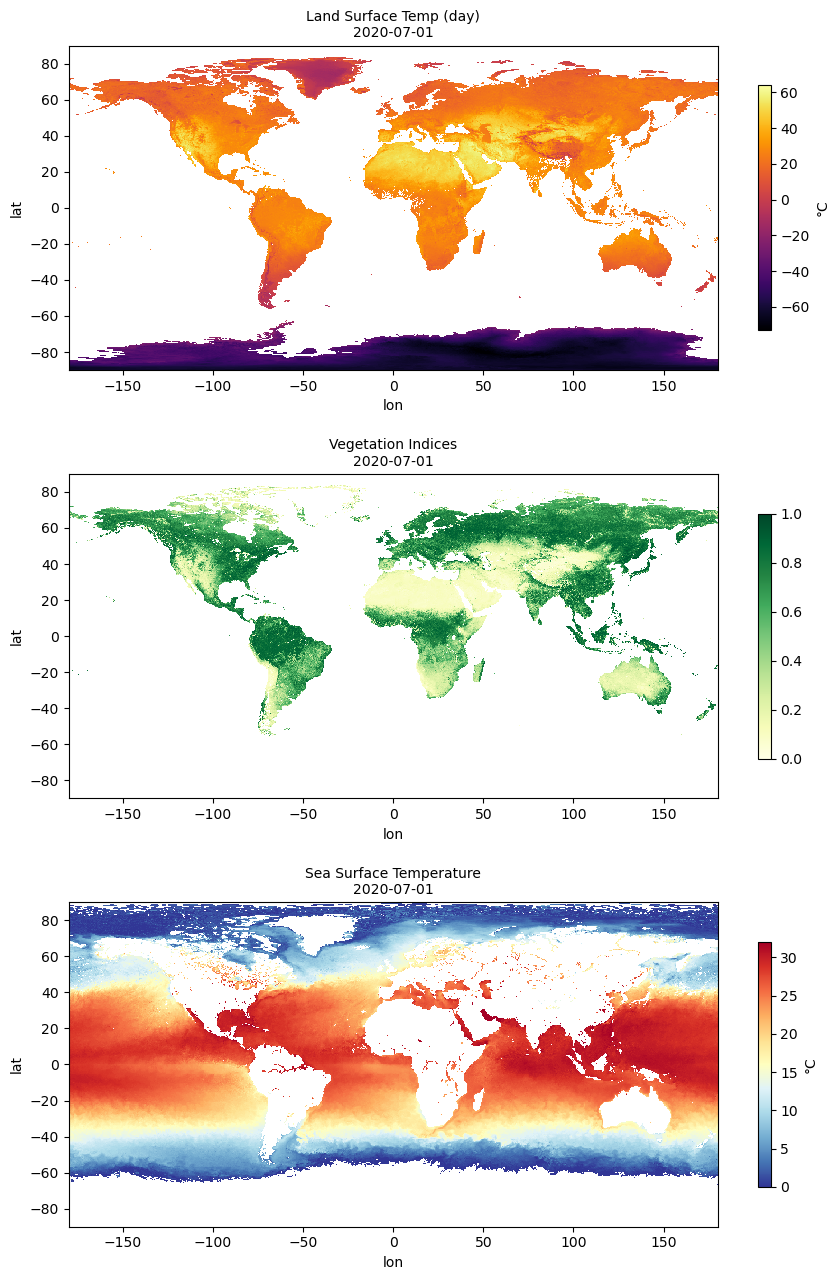

In [10]:
fig, axes = plt.subplots(3, 1, figsize=(9, 13))
lst_c = Grid(lst.layer, lst.date, lst.values - 273.15, lst.lats, lst.lons, "°C", "Land Surface Temp (day)")
lst_c.plot(axes[0], cmap="inferno")
ndvi.plot(axes[1], cmap="YlGn", vmin=0, vmax=1)
sst.plot(axes[2], cmap="RdYlBu_r")
for ax in axes:
    ax.set_xlabel("lon"); ax.set_ylabel("lat")
plt.tight_layout()

### A first time series

A quick end-to-end test over time: the area-weighted mean of Sahara daytime land surface temperature for every July.
Expect year-to-year variation of a degree or two. This is 26 requests on the first run and instant after that.

count    27.00
mean     47.69
std       1.52
min      41.77
25%      47.81
50%      48.05
75%      48.46
max      49.02
Name: Sahara July LST (°C), dtype: float64

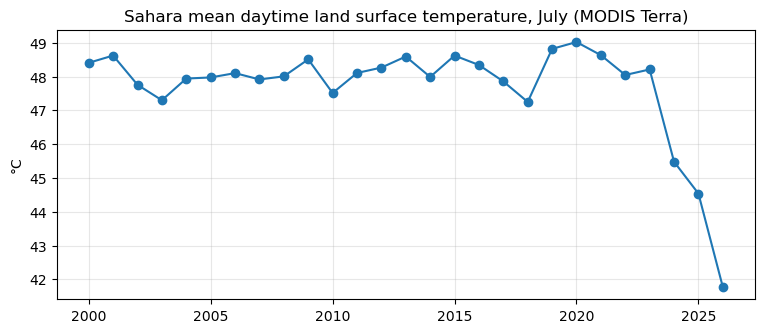

In [11]:
julys = [d for d in layer_dates(LST) if d.month == 7]
sahara_july = pd.Series({d.year: get_grid(LST, d).sel(**SAHARA).mean() - 273.15 for d in julys}, name="Sahara July LST (°C)")

ax = sahara_july.plot(marker="o", figsize=(9, 3.5))
ax.set_ylabel("°C"); ax.set_title("Sahara mean daytime land surface temperature, July (MODIS Terra)")
ax.grid(alpha=0.3)
sahara_july.describe().round(2)

### ⚠️ Caution: orbit drift after 2022

The July series above **drops by about 6 °C from 2023 to 2026**. This is a problem with the instrument, not climate.
Terra and Aqua are past their planned mission life and are no longer held in their usual orbits, so the local time
at which they pass overhead is changing:

- **Terra** used to pass at about 10:30 am / 10:30 pm and now passes **earlier**. An earlier morning pass sees cooler
  ground, and an earlier evening pass sees warmer ground. So Terra *day* LST falls and Terra *night* LST rises.
- **Aqua** used to pass at about 1:30 pm / 1:30 am and now passes **later**, so its *day* LST starts falling too.

The check below compares all four day/night series for the Sahara in July.

,Terra day,Terra night,Aqua day,Aqua night
2018,47.2,27.5,51.2,24.9
2019,48.8,28.1,53.2,25.5
2020,49.0,28.2,53.3,25.6
2021,48.6,28.3,52.8,25.7
2022,48.0,28.1,53.1,25.1
2023,48.2,29.4,53.9,26.0
2024,45.5,29.8,52.2,26.1
2025,44.5,30.3,52.6,25.6
2026,41.8,30.9,50.5,25.2


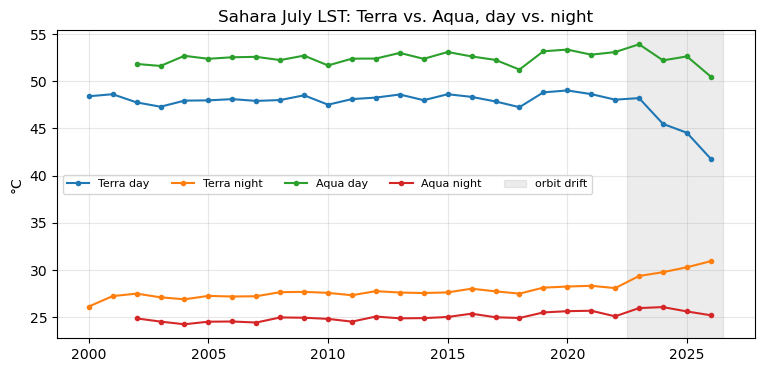

In [12]:
lst_layers = {
    "Terra day": "MODIS_Terra_L3_Land_Surface_Temp_Monthly_Day",
    "Terra night": "MODIS_Terra_L3_Land_Surface_Temp_Monthly_Night",
    "Aqua day": "MODIS_Aqua_L3_Land_Surface_Temp_Monthly_Day",
    "Aqua night": "MODIS_Aqua_L3_Land_Surface_Temp_Monthly_Night",
}
drift = pd.DataFrame({
    name: {d.year: get_grid(L, d).sel(**SAHARA).mean() - 273.15 for d in layer_dates(L) if d.month == 7}
    for name, L in lst_layers.items()
})
ax = drift.plot(marker=".", figsize=(9, 4))
ax.axvspan(2022.5, drift.index.max() + 0.5, color="grey", alpha=0.15, label="orbit drift")
ax.set_ylabel("°C"); ax.set_title("Sahara July LST: Terra vs. Aqua, day vs. night"); ax.grid(alpha=0.3); ax.legend(ncol=5, fontsize=8)
drift.loc[2018:].round(1)

**What this means for the project:** treat **2000/2002–2022** as the reliable period for trends in anything that
depends on time of day (mainly land surface temperature, and to a lesser degree SST and cloud layers).
If a story needs recent years, either show the drift openly or use a quantity that changes less with time of day.
NDVI and snow come from composites over many days and are less affected, but check them the same way in Phase 2.

## Phase 1 summary

Helpers available for the next phases:

| Helper | Purpose |
|---|---|
| `catalog`, `modis`, `monthly_summary` | layer metadata and date coverage |
| `find_layers("keyword")` | search MODIS layers |
| `layer_dates(layer)` | every available date (gaps excluded) |
| `load_colormap(layer)` | parsed color-to-value lookup |
| `get_grid(layer, date, bbox, width)` | decoded `Grid` (`.values`, `.sel()`, `.mean()`, `.coverage()`, `.plot()`) |

**Known data issues:** satellite orbit drift after 2022 (above), transparent values such as 0% snow decode to NaN,
and values are binned (about 0.6 K steps for LST).

**Next (Phase 2):** for land surface temperature, NDVI, snow and SST, make January/July maps across years, regional time series,
seasonal cycles, and anomaly maps against a 2001–2010 baseline.